# DEEP NEURAL NETWORKS - ASSIGNMENT 2: CNN FOR IMAGE CLASSIFICATION

## Convolutional Neural Networks: Custom Implementation vs Transfer Learning

STUDENT INFORMATION (REQUIRED - DO NOT DELETE)

BITS ID: 20256AC05606

Name: VANSHIKA SAXENA

Email: 2025ac05606@wilp.bits-pilani.ac.in

Date: 26-07-2026

In [3]:
# Import Required Libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import confusion_matrix, classification_report
import time
import json
import os
import random
import zipfile

In [4]:
# Deep learning frameworks (choose Keras or PyTorch)
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader
# For image processing
from PIL import Image
import cv2

### 1.1 Dataset Selection and Loading

TODO: Load your chosen dataset

In [5]:
!wget -O PetImages.zip https://download.microsoft.com/download/3/E/1/3E1C3F21-ECDB-4869-8368-6DEBA77B919F/kagglecatsanddogs_5340.zip

--2026-07-26 09:56:41--  https://download.microsoft.com/download/3/E/1/3E1C3F21-ECDB-4869-8368-6DEBA77B919F/kagglecatsanddogs_5340.zip
Resolving download.microsoft.com (download.microsoft.com)... 23.62.176.164, 2600:1406:5e00:392::317f, 2600:1406:5e00:389::317f
Connecting to download.microsoft.com (download.microsoft.com)|23.62.176.164|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 824887076 (787M) [application/octet-stream]
Saving to: ‘PetImages.zip’

PetImages.zip       100%[===================>] 786.67M  91.7MB/s    in 8.5s    

2026-07-26 09:56:49 (92.7 MB/s) - ‘PetImages.zip’ saved [824887076/824887076]



In [6]:
with zipfile.ZipFile("PetImages.zip", "r") as zip_ref:
    zip_ref.extractall()

print(os.listdir())

['.config', 'PetImages.zip', 'PetImages', 'CDLA-Permissive-2.0.pdf', 'readme[1].txt', 'sample_data']


In [7]:
data_dir = "PetImages"

print(os.listdir(data_dir))

['Dog', 'Cat']


In [8]:
from PIL import Image
import os

data_dir = "PetImages"

removed = 0

for category in ["Cat", "Dog"]:

    folder = os.path.join(data_dir, category)

    for filename in os.listdir(folder):

        path = os.path.join(folder, filename)

        try:
            with Image.open(path) as img:
                img.verify()

        except Exception:
            os.remove(path)
            removed += 1

print(f"Removed {removed} corrupted images.")

/usr/local/lib/python3.12/dist-packages/PIL/TiffImagePlugin.py:950: UserWarning: Truncated File Read
  warnings.warn(str(msg))


Removed 4 corrupted images.


In [9]:
cat_count = len(os.listdir(os.path.join(data_dir, "Cat")))
dog_count = len(os.listdir(os.path.join(data_dir, "Dog")))

print("Cats :", cat_count)
print("Dogs :", dog_count)

n_samples = cat_count + dog_count

samples_per_class = (
    f"min: {min(cat_count,dog_count)}, "
    f"max: {max(cat_count,dog_count)}, "
    f"avg: {(cat_count+dog_count)//2}"
)

Cats : 12499
Dogs : 12499


In [10]:
# REQUIRED: Fill in these metadata fields
dataset_name = "Microsoft Cats vs Dogs"
dataset_source = "https://www.microsoft.com/en-us/download/details.aspx?id=54765"
n_samples = n_samples  # TODO: Total number of images
n_classes = 2 # TODO: Number of classes
samples_per_class = samples_per_class
image_shape = [224, 224, 3]  # [height, width, channels]
problem_type = "classification"

In [11]:
# Primary metric selection
primary_metric = "Accuracy"
metric_justification = """
Accuracy is selected as the primary metric because the Cats vs Dogs dataset
contains two nearly balanced classes. It provides an appropriate overall
measure of classification performance while precision, recall, and F1-score
are also reported for a complete evaluation.
"""

In [12]:
print("DATASET INFORMATION")
print(f"Dataset: {dataset_name}")
print(f"Source: {dataset_source}")
print(f"Total Samples: {n_samples}")
print(f"Number of Classes: {n_classes}")
print(f"Samples per Class: {samples_per_class}")
print(f"Image Shape: {image_shape}")
print(f"Primary Metric: {primary_metric}")
print(f"Metric Justification: {metric_justification}")

DATASET INFORMATION
Dataset: Microsoft Cats vs Dogs
Source: https://www.microsoft.com/en-us/download/details.aspx?id=54765
Total Samples: 24998
Number of Classes: 2
Samples per Class: min: 12499, max: 12499, avg: 12499
Image Shape: [224, 224, 3]
Primary Metric: Accuracy
Metric Justification: 
Accuracy is selected as the primary metric because the Cats vs Dogs dataset
contains two nearly balanced classes. It provides an appropriate overall
measure of classification performance while precision, recall, and F1-score
are also reported for a complete evaluation.



### 1.2 Data Exploration and Visualization

- TODO: Show sample images from each class
- TODO: Plot class distribution
- TODO: Display image statistics

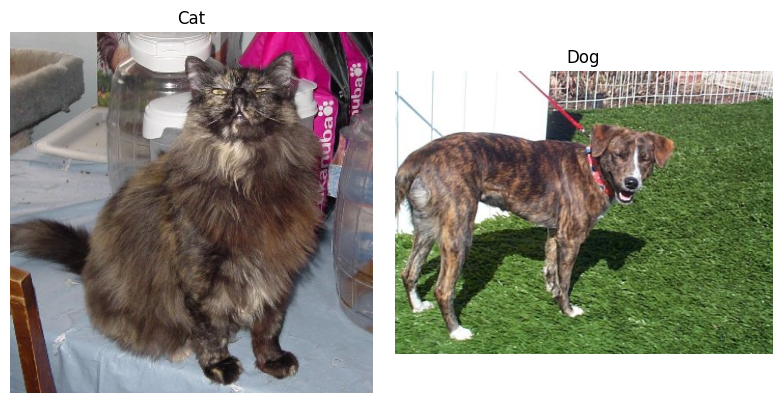

In [13]:
import matplotlib.pyplot as plt
from PIL import Image

fig, axes = plt.subplots(1, 2, figsize=(8,4))

cat_path = os.path.join(data_dir, "Cat", os.listdir(os.path.join(data_dir, "Cat"))[0])
dog_path = os.path.join(data_dir, "Dog", os.listdir(os.path.join(data_dir, "Dog"))[0])

cat_img = Image.open(cat_path)
dog_img = Image.open(dog_path)

axes[0].imshow(cat_img)
axes[0].set_title("Cat")
axes[0].axis("off")

axes[1].imshow(dog_img)
axes[1].set_title("Dog")
axes[1].axis("off")

plt.tight_layout()
plt.show()

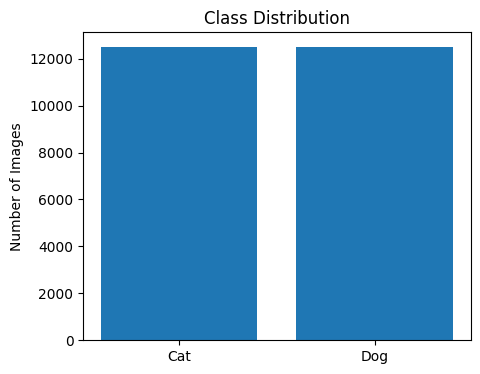

In [14]:
plt.figure(figsize=(5,4))

plt.bar(
    ["Cat", "Dog"],
    [cat_count, dog_count]
)

plt.title("Class Distribution")
plt.ylabel("Number of Images")

plt.show()

In [15]:
print("Image Statistics")
print(f"Total Images : {n_samples}")
print(f"Cat Images   : {cat_count}")
print(f"Dog Images   : {dog_count}")
print(f"Image Shape  : {image_shape}")

Image Statistics
Total Images : 24998
Cat Images   : 12499
Dog Images   : 12499
Image Shape  : [224, 224, 3]


### 1.3 Data Preprocessing
- TODO: Resize images to consistent size
- TODO: Normalize pixel values
- TODO: Split into train/test (90/10 or 85/15)

In [16]:
from torchvision import datasets, transforms
from torch.utils.data import random_split, DataLoader

In [17]:
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

In [18]:
dataset = datasets.ImageFolder(
    root=data_dir,
    transform=transform
)

print("Classes:", dataset.classes)

Classes: ['Cat', 'Dog']


In [19]:
train_size = int(0.9 * len(dataset))
test_size = len(dataset) - train_size

train_dataset, test_dataset = random_split(
    dataset,
    [train_size, test_size]
)

In [20]:
batch_size = 32

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False
)

In [21]:
# REQUIRED: Document your split
train_test_ratio = "90/10"
train_samples = len(train_dataset)  # TODO: Number of training samples
test_samples = len(test_dataset)  # TODO: Number of test samples

In [22]:
print(f"\nTrain/Test Split: {train_test_ratio}")
print(f"Training Samples: {train_samples}")
print(f"Test Samples: {test_samples}")


Train/Test Split: 90/10
Training Samples: 22498
Test Samples: 2500


### 2.1 Custom CNN Architecture Design
- TODO: Define your CNN architecture
- TODO: Ensure Global Average Pooling is included (MANDATORY)
- TODO: Use Conv2D, MaxPooling2D/AvgPooling2D, GlobalAveragePooling2D, Dense

In [23]:
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

cuda


In [26]:
def build_custom_cnn(input_shape, n_classes):
    """
    Build custom CNN architecture

    Args:
        input_shape: tuple (height, width, channels)
        n_classes: number of output classes

    Returns:
        model: compiled CNN model
    """
    # TODO: Implement your CNN architecture
    model = nn.Sequential(

        nn.Conv2d(3, 32, kernel_size=3, padding=1),
        nn.ReLU(),
        nn.MaxPool2d(2),

        nn.Conv2d(32, 64, kernel_size=3, padding=1),
        nn.ReLU(),
        nn.MaxPool2d(2),

        nn.Conv2d(64, 128, kernel_size=3, padding=1),
        nn.ReLU(),
        nn.MaxPool2d(2),

        # Global Average Pooling (MANDATORY)
        nn.AdaptiveAvgPool2d((1, 1)),

        nn.Flatten(),

        nn.Linear(128, n_classes)
    )
    # Must include Global Average Pooling
    return model

In [27]:
# TODO: Create model instance
custom_cnn = build_custom_cnn(image_shape, n_classes)
custom_cnn = custom_cnn.to(device)

In [28]:
# TODO: Compile model
criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    custom_cnn.parameters(),
    lr=0.001
)
# For Keras: model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
# For PyTorch: define optimizer and loss function


In [31]:
print("Custom CNN :",custom_cnn)
print("Loss Function :",criterion)
print("Optimizer :",optimizer)

Custom CNN : Sequential(
  (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (1): ReLU()
  (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (4): ReLU()
  (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (6): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (7): ReLU()
  (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (9): AdaptiveAvgPool2d(output_size=(1, 1))
  (10): Flatten(start_dim=1, end_dim=-1)
  (11): Linear(in_features=128, out_features=2, bias=True)
)
Loss Function : CrossEntropyLoss()
Optimizer : Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0
)


### 2.2 Train Custom CNN

In [32]:
print("\nCUSTOM CNN TRAINING")
# Track training time
custom_cnn_start_time = time.time()


CUSTOM CNN TRAINING


In [33]:
# TODO: Train your model
learning_rate = 0.001
num_epochs = 30
batch_size = 32
optimizer_name = "Adam"

custom_train_losses = []

for epoch in range(num_epochs):

    custom_cnn.train()

    running_loss = 0.0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = custom_cnn(images)

        loss = criterion(outputs, labels)

        loss.backward()

        optimizer.step()

        running_loss += loss.item()

    epoch_loss = running_loss / len(train_loader)

    custom_train_losses.append(epoch_loss)

    print(f"Epoch [{epoch+1}/{num_epochs}] Loss: {epoch_loss:.4f}")

custom_cnn_training_time = time.time() - custom_cnn_start_time

custom_cnn_initial_loss = custom_train_losses[0]
custom_cnn_final_loss = custom_train_losses[-1]
# For Keras: history = custom_cnn.fit(X_train, y_train, epochs=20, batch_size=32, validation_split=0.1)
# For PyTorch: write training loop

/usr/local/lib/python3.12/dist-packages/PIL/TiffImagePlugin.py:950: UserWarning: Truncated File Read
  warnings.warn(str(msg))


Epoch [1/30] Loss: 0.6529
Epoch [2/30] Loss: 0.5941
Epoch [3/30] Loss: 0.5577
Epoch [4/30] Loss: 0.5375
Epoch [5/30] Loss: 0.5239
Epoch [6/30] Loss: 0.5096
Epoch [7/30] Loss: 0.4973
Epoch [8/30] Loss: 0.4827
Epoch [9/30] Loss: 0.4702
Epoch [10/30] Loss: 0.4560
Epoch [11/30] Loss: 0.4457
Epoch [12/30] Loss: 0.4341
Epoch [13/30] Loss: 0.4236
Epoch [14/30] Loss: 0.4079
Epoch [15/30] Loss: 0.3944
Epoch [16/30] Loss: 0.3808
Epoch [17/30] Loss: 0.3731
Epoch [18/30] Loss: 0.3598
Epoch [19/30] Loss: 0.3539
Epoch [20/30] Loss: 0.3452
Epoch [21/30] Loss: 0.3346
Epoch [22/30] Loss: 0.3375
Epoch [23/30] Loss: 0.3301
Epoch [24/30] Loss: 0.3107
Epoch [25/30] Loss: 0.2980
Epoch [26/30] Loss: 0.3004
Epoch [27/30] Loss: 0.2956
Epoch [28/30] Loss: 0.2804
Epoch [29/30] Loss: 0.2805
Epoch [30/30] Loss: 0.2656


In [34]:
custom_cnn_training_time = time.time() - custom_cnn_start_time

In [35]:
# REQUIRED: Track initial and final loss
custom_cnn_initial_loss = custom_train_losses[0]  # TODO: Get from training history (first epoch)
custom_cnn_final_loss = custom_train_losses[-1]  # TODO: Get from training history (last epoch)

In [36]:
print(f"Training completed in {custom_cnn_training_time:.2f} seconds")
print(f"Initial Loss: {custom_cnn_initial_loss:.4f}")
print(f"Final Loss: {custom_cnn_final_loss:.4f}")

Training completed in 3718.19 seconds
Initial Loss: 0.6529
Final Loss: 0.2656


In [37]:
print("\nCUSTOM CNN EVALUATION")


CUSTOM CNN EVALUATION


### 2.3 Evaluate Custom CNN
- TODO: Make predictions on test set
- TODO: Calculate all 4 required metrics

In [38]:
custom_cnn.eval()

custom_y_true = []
custom_y_pred = []

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = custom_cnn(images)

        _, predicted = torch.max(outputs, 1)

        custom_y_true.extend(labels.cpu().numpy())
        custom_y_pred.extend(predicted.cpu().numpy())

In [39]:
# CRITICAL: These MUST be calculated from your actual results
# DO NOT submit with 0.0 values - autograder will detect this
# REQUIRED: Calculate all 4 metrics
custom_cnn_accuracy = accuracy_score(custom_y_true, custom_y_pred)
  # TODO: accuracy_score(y_test, y_pred)
custom_cnn_precision = precision_score(
    custom_y_true,
    custom_y_pred,
    average="macro"
)  # TODO: precision_score(y_test, y_pred, average='macro')
custom_cnn_recall = recall_score(
    custom_y_true,
    custom_y_pred,
    average="macro"
)  # TODO: recall_score(y_test, y_pred, average='macro')
custom_cnn_f1 = f1_score(
    custom_y_true,
    custom_y_pred,
    average="macro"
)  # TODO: f1_score(y_test, y_pred, average='macro')

In [40]:
print("\nCustom CNN Performance:")
print(f"Accuracy:  {custom_cnn_accuracy:.4f}")
print(f"Precision: {custom_cnn_precision:.4f}")
print(f"Recall:    {custom_cnn_recall:.4f}")
print(f"F1-Score:  {custom_cnn_f1:.4f}")


Custom CNN Performance:
Accuracy:  0.8824
Precision: 0.8825
Recall:    0.8823
F1-Score:  0.8824


### 2.4 Visualize Custom CNN Results
- TODO: Plot training loss curve
- TODO: Plot confusion matrix
- TODO: Show sample predictions

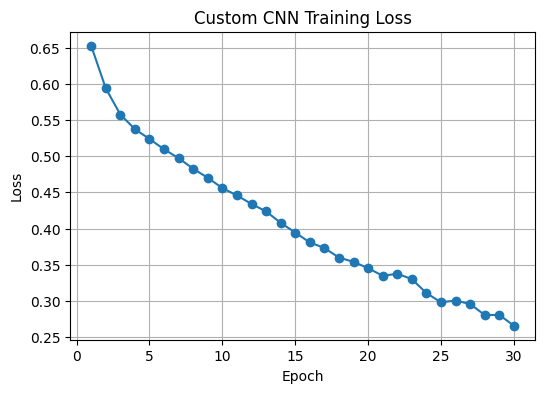

In [41]:
plt.figure(figsize=(6,4))

plt.plot(
    range(1, len(custom_train_losses)+1),
    custom_train_losses,
    marker='o'
)

plt.title("Custom CNN Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.grid(True)

plt.show()

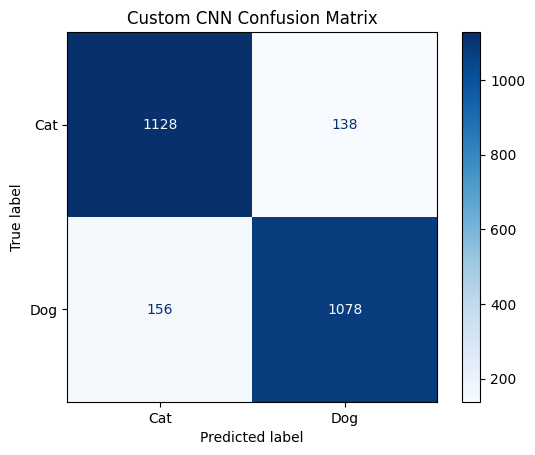

In [42]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
cm_custom = confusion_matrix(
    custom_y_true,
    custom_y_pred
)

ConfusionMatrixDisplay(
    confusion_matrix=cm_custom,
    display_labels=dataset.classes
).plot(cmap="Blues")

plt.title("Custom CNN Confusion Matrix")

plt.show()

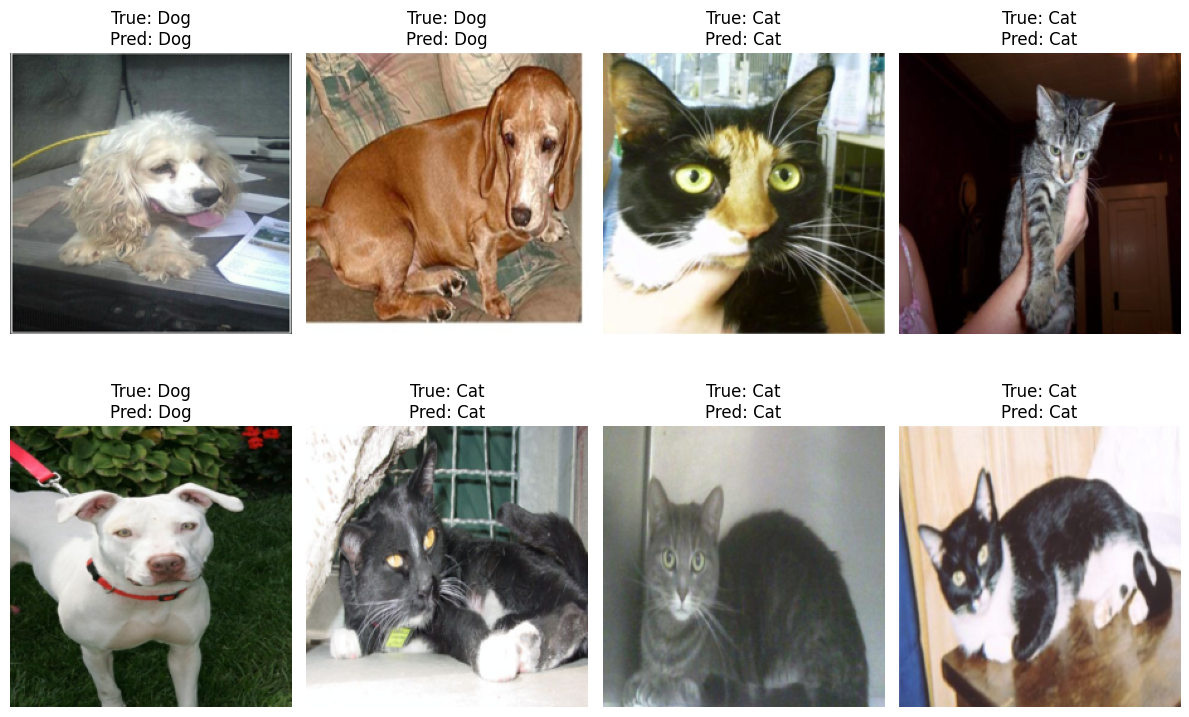

In [43]:
custom_cnn.eval()

images, labels = next(iter(test_loader))

images = images.to(device)

with torch.no_grad():

    outputs = custom_cnn(images)

    _, predictions = torch.max(outputs, 1)

images = images.cpu()

mean = np.array([0.485, 0.456, 0.406])
std = np.array([0.229, 0.224, 0.225])

plt.figure(figsize=(12,8))

for i in range(8):

    plt.subplot(2,4,i+1)

    img = images[i].permute(1,2,0).numpy()

    img = img * std + mean
    img = np.clip(img,0,1)

    plt.imshow(img)

    plt.title(
        f"True: {dataset.classes[labels[i]]}\nPred: {dataset.classes[predictions[i].item()]}"
    )

    plt.axis("off")

plt.tight_layout()

plt.show()

### 3.1 Load Pre-trained Model and Modify Architecture

In [44]:
print("\n" + "="*70)
print("TRANSFER LEARNING IMPLEMENTATION")


TRANSFER LEARNING IMPLEMENTATION


In [45]:
# TODO: Choose and load pre-trained model
pretrained_model_name = "ResNet18"

In [46]:
def build_transfer_learning_model(base_model_name, input_shape, n_classes):
    """
    Build transfer learning model

    Args:
        base_model_name: string (ResNet18/ResNet50/VGG16/VGG19)
        input_shape: tuple (height, width, channels)
        n_classes: number of output classes

    Returns:
        model: compiled transfer learning model
    """
    # TODO: Load pre-trained model without top layers
    if base_model_name == "ResNet18":
        model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)

    elif base_model_name == "ResNet50":
        model = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)

    else:
        raise ValueError("Unsupported model.")

    # Freeze ALL layers
    # TODO: Freeze base layers
    for param in model.parameters():
        param.requires_grad = False

    # Fine-tune ONLY layer4
    for param in model.layer4.parameters():
        param.requires_grad = True

    # Replace classification head
    # TODO: Add Global Average Pooling + custom classification head
    num_features = model.fc.in_features
    # TODO: Compile model
    model.fc = nn.Linear(
        num_features,
        n_classes
    )


    return model

In [47]:
# TODO: Create transfer learning model
transfer_model = build_transfer_learning_model(pretrained_model_name, image_shape, n_classes)

transfer_model = transfer_model.to(device)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 138MB/s]


In [48]:
criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(

    filter(
        lambda p: p.requires_grad,
        transfer_model.parameters()
    ),

    lr=1e-4
)

In [49]:
# REQUIRED: Count layers and parameters
frozen_layers = 0
trainable_layers = 0

for param in transfer_model.parameters():

    if param.requires_grad:
        trainable_layers += 1
    else:
        frozen_layers += 1
frozen_layers = frozen_layers  # TODO: Count frozen layers
trainable_layers = trainable_layers  # TODO: Count trainable layers
total_parameters = sum(
    p.numel()
    for p in transfer_model.parameters()
)
  # TODO: Total parameters
trainable_parameters =  sum(
    p.numel()
    for p in transfer_model.parameters()
    if p.requires_grad
)  # TODO: Trainable parameters only

In [50]:
print(f"Base Model: {pretrained_model_name}")
print(f"Frozen Layers: {frozen_layers}")
print(f"Trainable Layers: {trainable_layers}")
print(f"Total Parameters: {total_parameters:,}")
print(f"Trainable Parameters: {trainable_parameters:,}")
print(f"Using Global Average Pooling: YES")

Base Model: ResNet18
Frozen Layers: 45
Trainable Layers: 17
Total Parameters: 11,177,538
Trainable Parameters: 8,394,754
Using Global Average Pooling: YES


### 3.2 Train Transfer Learning Model

In [51]:
print("\nTraining Transfer Learning Model...")


Training Transfer Learning Model...


In [52]:
# Training configuration
tl_learning_rate = 0.0001
tl_epochs = 15
tl_batch_size = 32
tl_optimizer = "Adam"

In [54]:
# Track training time
tl_start_time = time.time()

In [55]:
# TODO: Train model


num_epochs = tl_epochs

transfer_train_losses = []

for epoch in range(num_epochs):

    transfer_model.train()

    running_loss = 0.0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = transfer_model(images)

        loss = criterion(outputs, labels)

        loss.backward()

        optimizer.step()

        running_loss += loss.item()

    epoch_loss = running_loss / len(train_loader)

    transfer_train_losses.append(epoch_loss)

    print(f"Epoch [{epoch+1}/{num_epochs}] Loss: {epoch_loss:.4f}")

tl_training_time = time.time() - tl_start_time

transfer_learning_initial_loss = transfer_train_losses[0]
transfer_learning_final_loss = transfer_train_losses[-1]

# For Keras: history = transfer_model.fit(X_train, y_train, epochs=10, batch_size=32)
# For PyTorch: write training loop

/usr/local/lib/python3.12/dist-packages/PIL/TiffImagePlugin.py:950: UserWarning: Truncated File Read
  warnings.warn(str(msg))


Epoch [1/15] Loss: 0.0702
Epoch [2/15] Loss: 0.0252
Epoch [3/15] Loss: 0.0192
Epoch [4/15] Loss: 0.0189
Epoch [5/15] Loss: 0.0099
Epoch [6/15] Loss: 0.0139
Epoch [7/15] Loss: 0.0097
Epoch [8/15] Loss: 0.0071
Epoch [9/15] Loss: 0.0051
Epoch [10/15] Loss: 0.0128
Epoch [11/15] Loss: 0.0108
Epoch [12/15] Loss: 0.0089
Epoch [13/15] Loss: 0.0125
Epoch [14/15] Loss: 0.0120
Epoch [15/15] Loss: 0.0104


In [56]:
tl_training_time = time.time() - tl_start_time

In [57]:
# REQUIRED: Track initial and final loss
tl_initial_loss = transfer_learning_initial_loss  # TODO: Get from training history (first epoch)
tl_final_loss = transfer_learning_final_loss # TODO: Get from training history (last epoch)

In [58]:
print(f"Training completed in {tl_training_time:.2f} seconds")
print(f"Initial Loss: {tl_initial_loss:.4f}")
print(f"Final Loss: {tl_final_loss:.4f}")

Training completed in 1826.86 seconds
Initial Loss: 0.0702
Final Loss: 0.0104


### 3.3 Evaluate Transfer Learning Model
- TODO: Make predictions on test set
- TODO: Calculate all 4 required metrics

In [59]:
print("\nTRANSFER LEARNING EVALUATION")

transfer_model.eval()

tl_y_true = []
tl_y_pred = []

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = transfer_model(images)

        _, predicted = torch.max(outputs, 1)

        tl_y_true.extend(labels.cpu().numpy())
        tl_y_pred.extend(predicted.cpu().numpy())


TRANSFER LEARNING EVALUATION


In [60]:
# REQUIRED: Calculate all 4 metrics
tl_accuracy = accuracy_score(
    tl_y_true,
    tl_y_pred
)
  # TODO: accuracy_score(y_test, y_pred)
tl_precision = precision_score(
    tl_y_true,
    tl_y_pred,
    average="macro"
)  # TODO: precision_score(y_test, y_pred, average='macro')
tl_recall =  recall_score(
    tl_y_true,
    tl_y_pred,
    average="macro"
)  # TODO: recall_score(y_test, y_pred, average='macro')
tl_f1 = f1_score(
    tl_y_true,
    tl_y_pred,
    average="macro"
)
  # TODO: f1_score(y_test, y_pred, average='macro')

In [61]:
print("\nTransfer Learning Performance:")
print(f"Accuracy:  {tl_accuracy:.4f}")
print(f"Precision: {tl_precision:.4f}")
print(f"Recall:    {tl_recall:.4f}")
print(f"F1-Score:  {tl_f1:.4f}")


Transfer Learning Performance:
Accuracy:  0.9888
Precision: 0.9888
Recall:    0.9888
F1-Score:  0.9888


### 3.4 Visualize Transfer Learning Results
- TODO: Plot training curves (loss and accuracy)
- TODO: Plot confusion matrix
- TODO: Show sample predictions

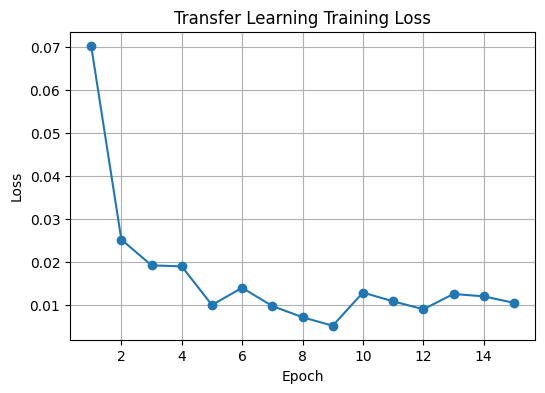

In [62]:
plt.figure(figsize=(6,4))

plt.plot(
    range(1, len(transfer_train_losses)+1),
    transfer_train_losses,
    marker='o'
)

plt.title("Transfer Learning Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.grid(True)

plt.show()

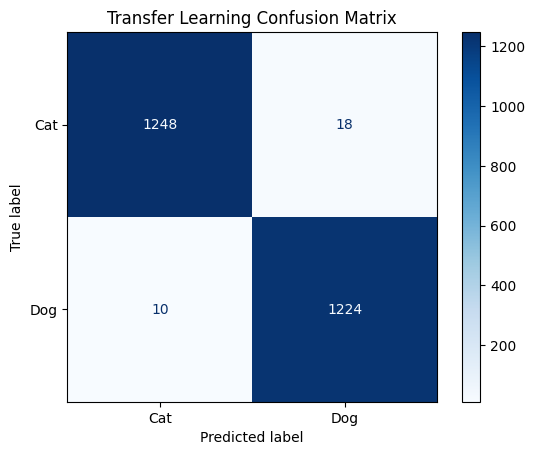

In [63]:
cm_transfer = confusion_matrix(
    tl_y_true,
    tl_y_pred
)

ConfusionMatrixDisplay(
    confusion_matrix=cm_transfer,
    display_labels=dataset.classes
).plot(cmap="Blues")

plt.title("Transfer Learning Confusion Matrix")

plt.show()

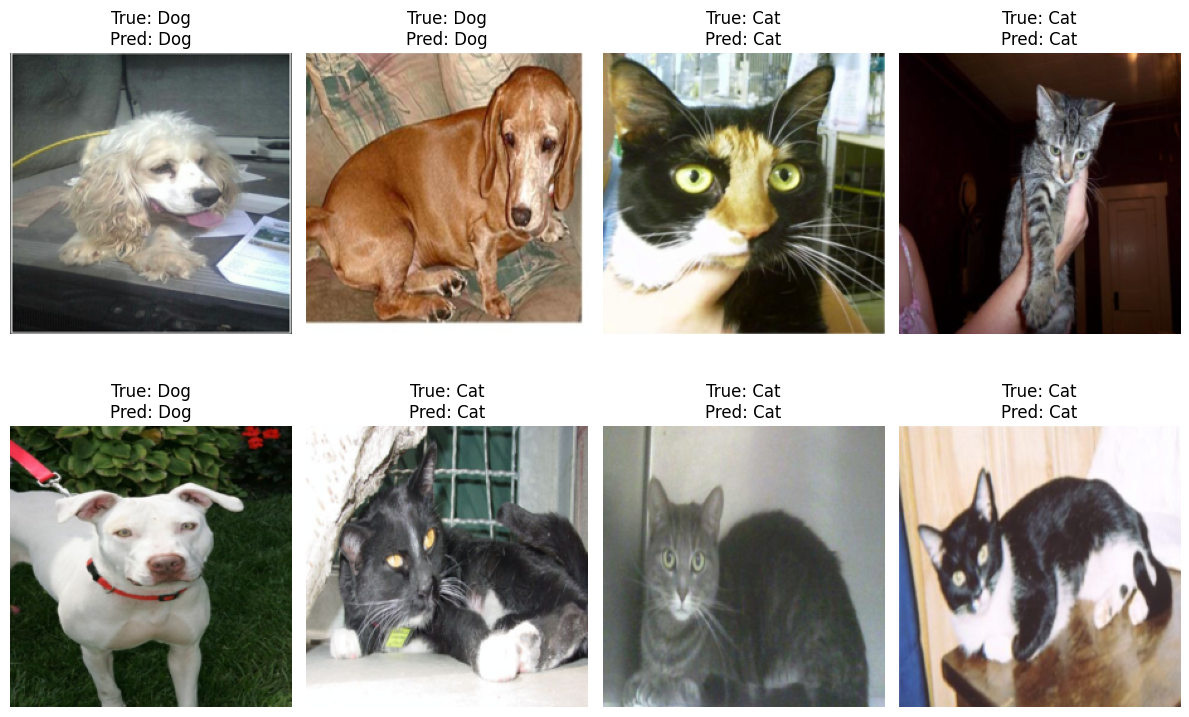

In [64]:
transfer_model.eval()

images, labels = next(iter(test_loader))

images = images.to(device)

with torch.no_grad():

    outputs = transfer_model(images)

    _, predictions = torch.max(outputs, 1)

images = images.cpu()

mean = np.array([0.485, 0.456, 0.406])
std = np.array([0.229, 0.224, 0.225])

plt.figure(figsize=(12,8))

for i in range(8):

    plt.subplot(2,4,i+1)

    img = images[i].permute(1,2,0).numpy()

    img = img * std + mean
    img = np.clip(img,0,1)

    plt.imshow(img)

    plt.title(
        f"True: {dataset.classes[labels[i]]}\nPred: {dataset.classes[predictions[i].item()]}"
    )

    plt.axis("off")

plt.tight_layout()

plt.show()

### 4.1 Metrics Comparison

In [66]:
custom_cnn_parameters = sum(
    p.numel() for p in custom_cnn.parameters()
)

In [67]:
comparison_df = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'Training Time (s)', 'Parameters'],
    'Custom CNN': [
        custom_cnn_accuracy,
        custom_cnn_precision,
        custom_cnn_recall,
        custom_cnn_f1,
        custom_cnn_training_time,
        custom_cnn_parameters  # TODO: Fill with custom CNN total parameters
    ],
    'Transfer Learning': [
        tl_accuracy,
        tl_precision,
        tl_recall,
        tl_f1,
        tl_training_time,
        trainable_parameters
    ]
})

In [68]:
print(comparison_df.to_string(index=False))

           Metric   Custom CNN  Transfer Learning
         Accuracy     0.882400       9.888000e-01
        Precision     0.882509       9.887791e-01
           Recall     0.882289       9.888391e-01
         F1-Score     0.882353       9.887990e-01
Training Time (s)  3718.191420       1.826865e+03
       Parameters 93506.000000       8.394754e+06


### 4.2 Visual Comparison
- TODO: Create bar plot comparing metrics
- TODO: Plot training curves comparison
- TODO: Create side-by-side confusion matrices

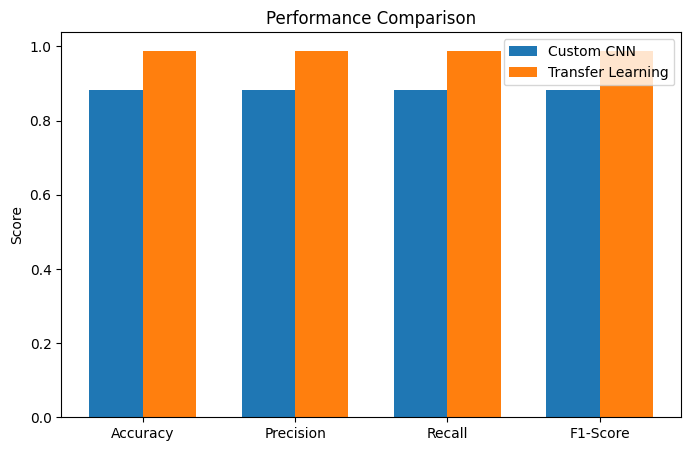

In [69]:
metrics = ["Accuracy", "Precision", "Recall", "F1-Score"]

custom_scores = [
    custom_cnn_accuracy,
    custom_cnn_precision,
    custom_cnn_recall,
    custom_cnn_f1
]

transfer_scores = [
    tl_accuracy,
    tl_precision,
    tl_recall,
    tl_f1
]

x = np.arange(len(metrics))
width = 0.35

plt.figure(figsize=(8,5))

plt.bar(x - width/2, custom_scores, width, label="Custom CNN")
plt.bar(x + width/2, transfer_scores, width, label="Transfer Learning")

plt.xticks(x, metrics)
plt.ylabel("Score")
plt.title("Performance Comparison")
plt.legend()

plt.show()

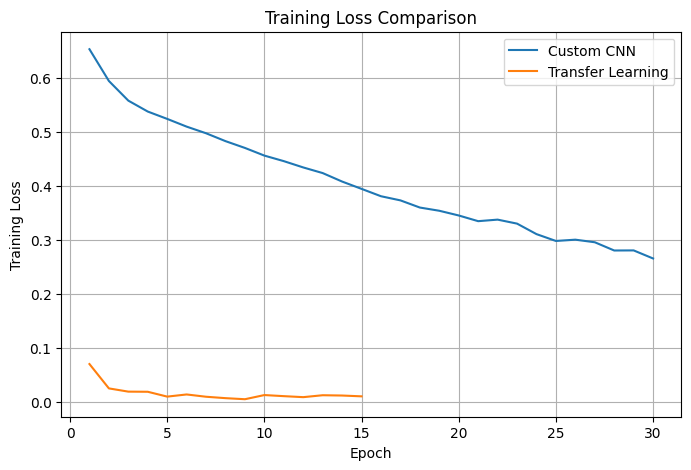

In [70]:
plt.figure(figsize=(8,5))

plt.plot(
    range(1, len(custom_train_losses)+1),
    custom_train_losses,
    label="Custom CNN"
)

plt.plot(
    range(1, len(transfer_train_losses)+1),
    transfer_train_losses,
    label="Transfer Learning"
)

plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.title("Training Loss Comparison")

plt.legend()
plt.grid(True)

plt.show()

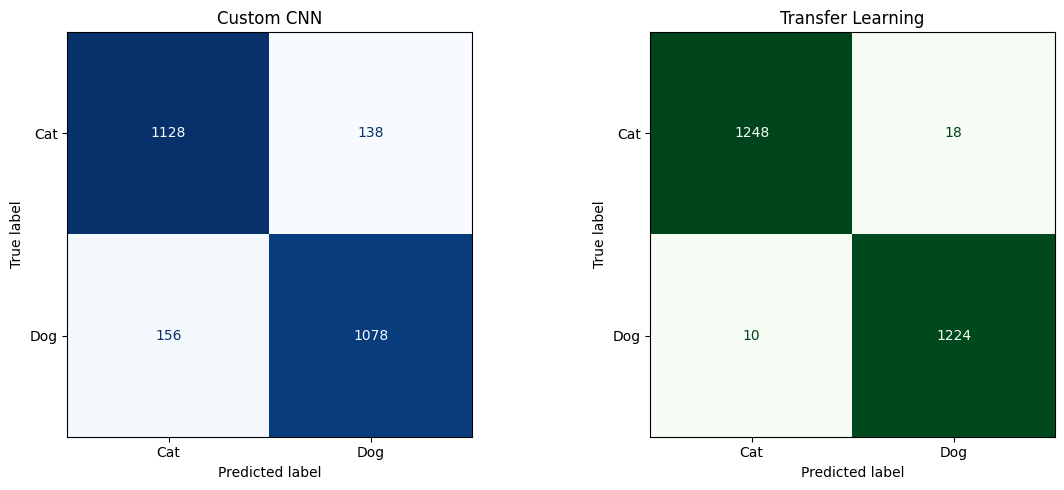

In [71]:
fig, axes = plt.subplots(1, 2, figsize=(12,5))

ConfusionMatrixDisplay(
    confusion_matrix=cm_custom,
    display_labels=dataset.classes
).plot(
    ax=axes[0],
    cmap="Blues",
    colorbar=False
)

axes[0].set_title("Custom CNN")

ConfusionMatrixDisplay(
    confusion_matrix=cm_transfer,
    display_labels=dataset.classes
).plot(
    ax=axes[1],
    cmap="Greens",
    colorbar=False
)

axes[1].set_title("Transfer Learning")

plt.tight_layout()
plt.show()

In [76]:
analysis_text = """
The transfer learning model achieved the best overall performance with an accuracy of 98.88, while the custom CNN achieved 88.24% accuracy. Similar improvements were observed in precision, recall, and F1-score, demonstrating the advantage of transfer learning on the Cats vs Dogs dataset.

The pre-trained ResNet18 benefited from features learned on ImageNet, enabling faster learning and better generalization than the custom CNN, which learned all features from scratch. Fine-tuning the last residual block further improved convergence while keeping most layers frozen.

Global Average Pooling (GAP) was used in both models to replace large fully connected layers. GAP reduced the number of trainable parameters in the classifier, minimized overfitting, and produced a simpler architecture.

The custom CNN required more training time because all convolutional layers were trained. Although ResNet18 has more total parameters, only the final classification head and the last residual block were fine-tuned, making transfer learning computationally efficient.

The custom CNN reduced training loss from 0.6529 to 0.2656 (59.3%), while transfer learning reduced loss from 0.0702 to 0.0104 (85.2%). Overall, transfer learning provided faster convergence, higher accuracy, and better generalization, making it the preferred approach for this dataset.
"""

In [77]:
# REQUIRED: Print analysis with word count
print("ANALYSIS")
print(analysis_text)
print(f"Analysis word count: {len(analysis_text.split())} words")
if len(analysis_text.split()) > 200:
    print("  Warning: Analysis exceeds 200 words (guideline)")
else:
    print(" Analysis within word count guideline")

ANALYSIS

The transfer learning model achieved the best overall performance with an accuracy of 98.88, while the custom CNN achieved 88.24% accuracy. Similar improvements were observed in precision, recall, and F1-score, demonstrating the advantage of transfer learning on the Cats vs Dogs dataset.

The pre-trained ResNet18 benefited from features learned on ImageNet, enabling faster learning and better generalization than the custom CNN, which learned all features from scratch. Fine-tuning the last residual block further improved convergence while keeping most layers frozen.

Global Average Pooling (GAP) was used in both models to replace large fully connected layers. GAP reduced the number of trainable parameters in the classifier, minimized overfitting, and produced a simpler architecture.

The custom CNN required more training time because all convolutional layers were trained. Although ResNet18 has more total parameters, only the final classification head and the last residual bloc

In [78]:
def get_assignment_results():
    """
    Generate complete assignment results in required format

    Returns:
        dict: Complete results with all required fields
    """

    framework_used = "pytorch"  # TODO: Change to "pytorch" if using PyTorch

    results = {
        # Dataset Information
        'dataset_name': dataset_name,
        'dataset_source': dataset_source,
        'n_samples': n_samples,
        'n_classes': n_classes,
        'samples_per_class': samples_per_class,
        'image_shape': image_shape,
        'problem_type': problem_type,
        'primary_metric': primary_metric,
        'metric_justification': metric_justification,
        'train_samples': train_samples,
        'test_samples': test_samples,
        'train_test_ratio': train_test_ratio,

        # Custom CNN Results
        'custom_cnn': {
            'framework': framework_used,
            'architecture': {
                'conv_layers': 3,  # TODO: Count your conv layers
                'pooling_layers': 3,  # TODO: Count your pooling layers
                'has_global_average_pooling': True,  # MUST be True
                'output_layer': 'softmax',
                'total_parameters': custom_cnn_parameters  # TODO: Calculate total parameters
            },
            'training_config': {
                'learning_rate': 0.001,  # TODO: Your actual learning rate
                'n_epochs': 30,  # TODO: Your actual epochs
                'batch_size': 32,  # TODO: Your actual batch size
                'optimizer': 'Adam',  # TODO: Your actual optimizer
                'loss_function': 'CrossEntropyLoss'  # TODO: Your actual loss
            },
            'initial_loss': custom_cnn_initial_loss,
            'final_loss': custom_cnn_final_loss,
            'training_time_seconds': custom_cnn_training_time,
            'accuracy': custom_cnn_accuracy,
            'precision': custom_cnn_precision,
            'recall': custom_cnn_recall,
            'f1_score': custom_cnn_f1
        },

        # Transfer Learning Results
        'transfer_learning': {
            'framework': framework_used,
            'base_model': pretrained_model_name,
            'frozen_layers': frozen_layers,
            'trainable_layers': trainable_layers,
            'has_global_average_pooling': True,  # MUST be True
            'total_parameters': total_parameters,
            'trainable_parameters': trainable_parameters,
            'training_config': {
                'learning_rate': tl_learning_rate,
                'n_epochs': tl_epochs,
                'batch_size': tl_batch_size,
                'optimizer': tl_optimizer,
                'loss_function': 'CrossEntropyLoss'
            },
            'initial_loss': tl_initial_loss,
            'final_loss': tl_final_loss,
            'training_time_seconds': tl_training_time,
            'accuracy': tl_accuracy,
            'precision': tl_precision,
            'recall': tl_recall,
            'f1_score': tl_f1
        },

        # Analysis
        'analysis': analysis_text,
        'analysis_word_count': len(analysis_text.split()),

        # Training Success Indicators
        'custom_cnn_loss_decreased': custom_cnn_final_loss < custom_cnn_initial_loss if custom_cnn_initial_loss and custom_cnn_final_loss else False,
        'transfer_learning_loss_decreased': tl_final_loss < tl_initial_loss if tl_initial_loss and tl_final_loss else False,
    }

    return results

In [79]:
# Generate and print results
try:
    assignment_results = get_assignment_results()
    print("ASSIGNMENT RESULTS SUMMARY")
    print(json.dumps(assignment_results, indent=2))

except Exception as e:
    print(f"\n  ERROR generating results: {str(e)}")
    print("Please ensure all variables are properly defined")

ASSIGNMENT RESULTS SUMMARY
{
  "dataset_name": "Microsoft Cats vs Dogs",
  "dataset_source": "https://www.microsoft.com/en-us/download/details.aspx?id=54765",
  "n_samples": 24998,
  "n_classes": 2,
  "samples_per_class": "min: 12499, max: 12499, avg: 12499",
  "image_shape": [
    224,
    224,
    3
  ],
  "problem_type": "classification",
  "primary_metric": "Accuracy",
  "metric_justification": "\nAccuracy is selected as the primary metric because the Cats vs Dogs dataset\ncontains two nearly balanced classes. It provides an appropriate overall\nmeasure of classification performance while precision, recall, and F1-score\nare also reported for a complete evaluation.\n",
  "train_samples": 22498,
  "test_samples": 2500,
  "train_test_ratio": "90/10",
  "custom_cnn": {
    "framework": "pytorch",
    "architecture": {
      "conv_layers": 3,
      "pooling_layers": 3,
      "has_global_average_pooling": true,
      "output_layer": "softmax",
      "total_parameters": 93506
    },
    

In [80]:
# Display system information
import platform
import sys
from datetime import datetime

In [81]:
print("ENVIRONMENT INFORMATION")
print("\n  REQUIRED: Add screenshot of your Google Colab/BITS Virtual Lab")
print("showing your account details in the cell below this one.")

# include the screen shot here

ENVIRONMENT INFORMATION

  REQUIRED: Add screenshot of your Google Colab/BITS Virtual Lab
showing your account details in the cell below this one.


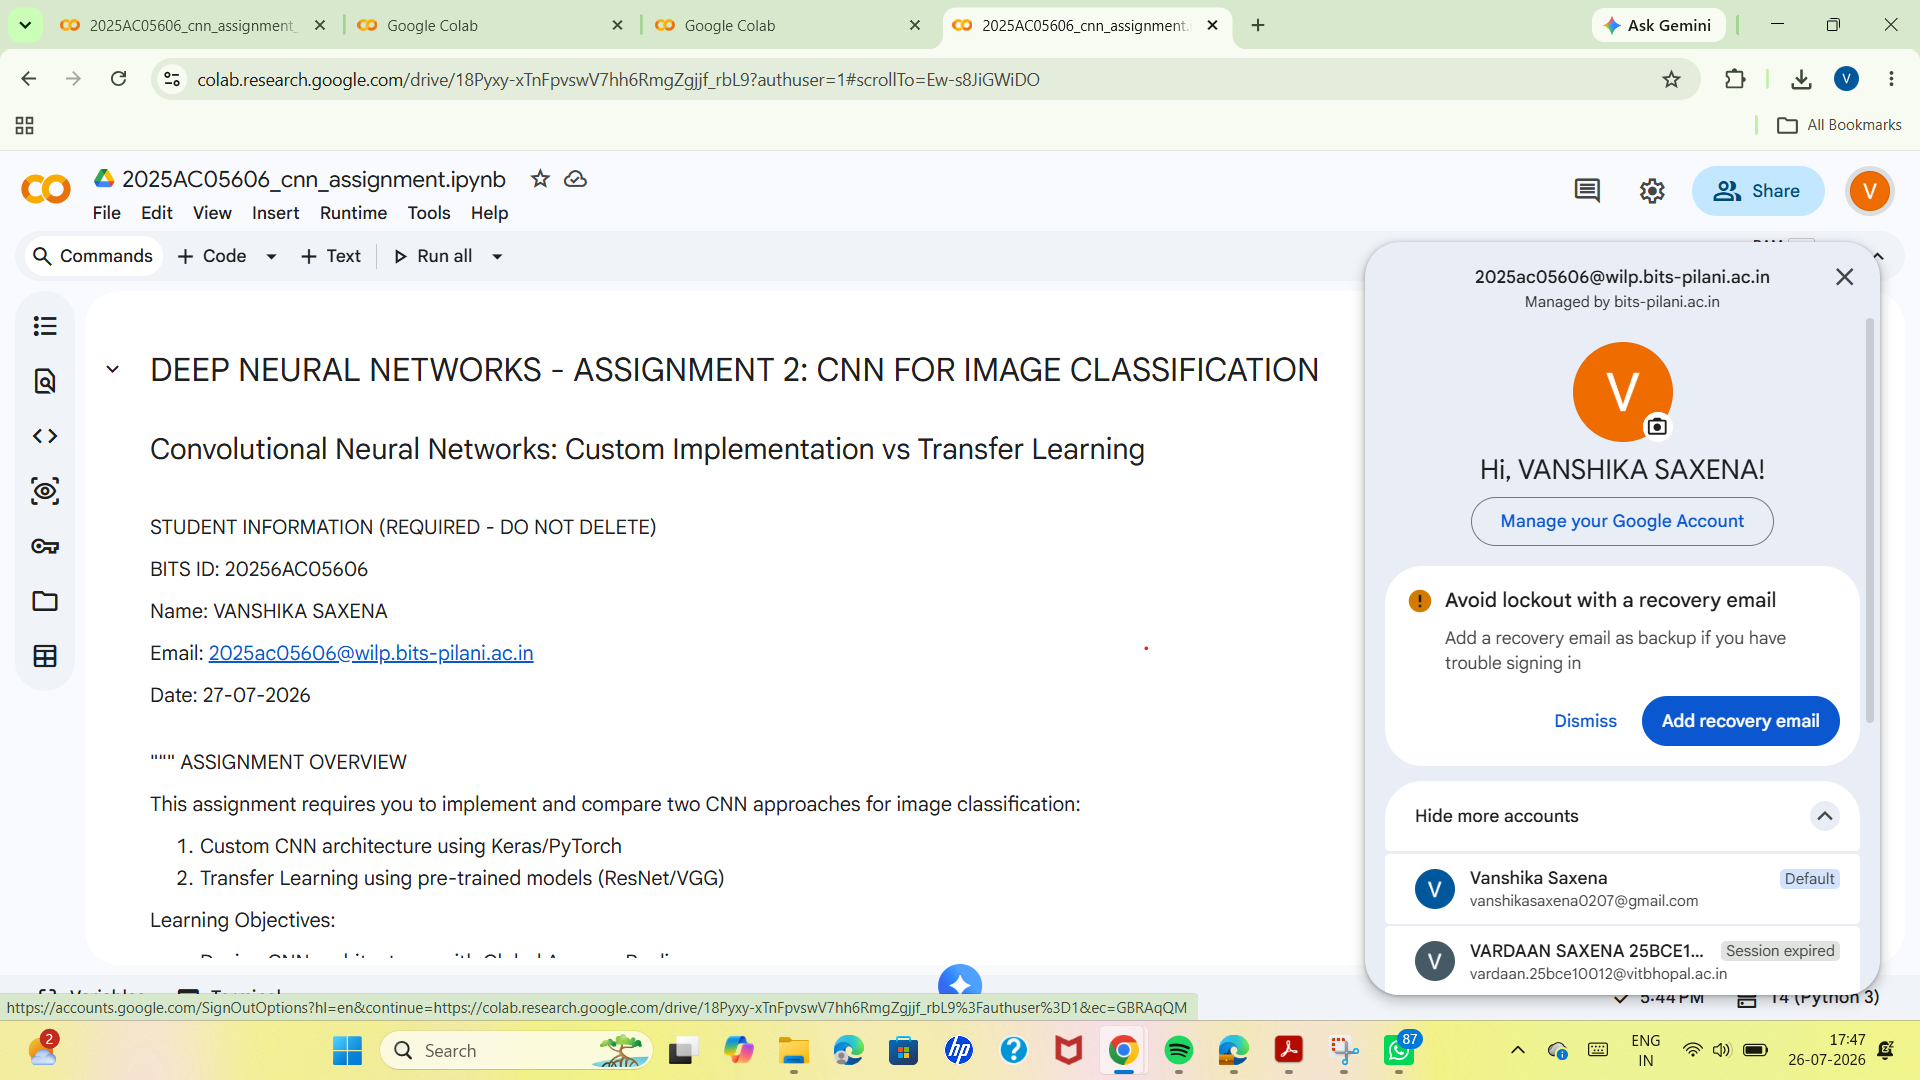